In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io

sns.set_theme(style="whitegrid")
%matplotlib inline

In [31]:
df=pd.read_csv(r"C:\Users\hp\OneDrive\Documents\data analytics\data\credit_data.csv")

In [35]:
df

,rownames,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,good,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846
1,2,good,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658
2,3,bad,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985
3,4,good,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325
4,5,good,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4449,4450,bad,1,rent,60,39,married,no,fixed,69,92.0,0.0,0.0,900,1020
4450,4451,good,22,owner,60,46,married,no,fixed,60,75.0,3000.0,600.0,950,1263
4451,4452,bad,0,owner,24,37,married,no,partime,60,90.0,3500.0,0.0,500,963
4452,4453,good,0,rent,48,23,single,no,freelance,49,140.0,0.0,0.0,550,550


In [36]:
df.head(5)

,rownames,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,good,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846
1,2,good,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658
2,3,bad,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985
3,4,good,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325
4,5,good,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910


In [37]:
df.tail(5)

,rownames,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
4449,4450,bad,1,rent,60,39,married,no,fixed,69,92.0,0.0,0.0,900,1020
4450,4451,good,22,owner,60,46,married,no,fixed,60,75.0,3000.0,600.0,950,1263
4451,4452,bad,0,owner,24,37,married,no,partime,60,90.0,3500.0,0.0,500,963
4452,4453,good,0,rent,48,23,single,no,freelance,49,140.0,0.0,0.0,550,550
4453,4454,good,5,owner,60,32,married,no,freelance,60,140.0,4000.0,1000.0,1350,1650


In [7]:
df.shape

(4454, 15)

In [8]:
df.size

66810

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4454 entries, 0 to 4453
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   rownames   4454 non-null   int64  
 1   Status     4454 non-null   str    
 2   Seniority  4454 non-null   int64  
 3   Home       4448 non-null   str    
 4   Time       4454 non-null   int64  
 5   Age        4454 non-null   int64  
 6   Marital    4453 non-null   str    
 7   Records    4454 non-null   str    
 8   Job        4452 non-null   str    
 9   Expenses   4454 non-null   int64  
 10  Income     4073 non-null   float64
 11  Assets     4407 non-null   float64
 12  Debt       4436 non-null   float64
 13  Amount     4454 non-null   int64  
 14  Price      4454 non-null   int64  
dtypes: float64(3), int64(7), str(5)
memory usage: 627.9 KB


In [10]:
df.columns

Index(['rownames', 'Status', 'Seniority', 'Home', 'Time', 'Age', 'Marital',
       'Records', 'Job', 'Expenses', 'Income', 'Assets', 'Debt', 'Amount',
       'Price'],
      dtype='str')

In [11]:
df.dtypes


rownames       int64
Status           str
Seniority      int64
Home             str
Time           int64
Age            int64
Marital          str
Records          str
Job              str
Expenses       int64
Income       float64
Assets       float64
Debt         float64
Amount         int64
Price          int64
dtype: object

In [12]:
df.isnull().sum()

rownames       0
Status         0
Seniority      0
Home           6
Time           0
Age            0
Marital        1
Records        0
Job            2
Expenses       0
Income       381
Assets        47
Debt          18
Amount         0
Price          0
dtype: int64

In [13]:
df.describe().round(2)

,rownames,Seniority,Time,Age,Expenses,Income,Assets,Debt,Amount,Price
count,4454.00,4454.00,4454.00,4454.00,4454.00,4073.00,4407.00,4436.00,4454.00,4454.00
mean,2227.50,7.99,46.44,37.08,55.57,141.69,5403.98,343.03,1038.92,1462.78
std,1285.90,8.17,14.66,10.98,19.52,80.75,11574.42,1245.99,474.55,628.13
min,1.00,0.00,6.00,18.00,35.00,6.00,0.00,0.00,100.00,105.00
25%,1114.25,2.00,36.00,28.00,35.00,90.00,0.00,0.00,700.00,1117.25
50%,2227.50,5.00,48.00,36.00,51.00,125.00,3000.00,0.00,1000.00,1400.00
75%,3340.75,12.00,60.00,45.00,72.00,170.00,6000.00,0.00,1300.00,1691.50
max,4454.00,48.00,72.00,68.00,180.00,959.00,300000.00,30000.00,5000.00,11140.00


In [38]:
df = df.drop(columns=['rownames'])

In [39]:
for col in ['Home', 'Marital', 'Job']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])
        df[col] = df[col].astype('category')

In [40]:
for col in ['Income', 'Assets', 'Debt']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

In [17]:
df["default"] = (df["Status"].str.lower() == "bad").astype(int)
df["records_flag"] = (df["Records"].str.lower() == "yes").astype(int)

In [18]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price,default,records_flag
0,good,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846,0,0
1,good,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658,0,0
2,bad,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985,1,1
3,good,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325,0,0
4,good,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910,0,0


In [19]:
df["debt_to_income"] = df["Debt"] / (df["Income"] + 1.0)
df["loan_to_price"] = df["Amount"] / (df["Price"] + 1.0)
df["log_income"] = np.log1p(df["Income"])
df["log_assets"] = np.log1p(df["Assets"])
df["log_amount"] = np.log1p(df["Amount"])

In [20]:
num_cols = ["Seniority", "Age", "Income", "Assets", "Debt", "Amount", "Price", "debt_to_income"]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Seniority,4454.0,7.986753,8.174306,0.0,2.00,5.0,12.0,48.000000
Age,4454.0,37.080377,10.984598,18.0,28.00,36.0,45.0,68.000000
Income,4454.0,140.260216,77.357696,6.0,93.00,125.0,164.0,959.000000
Assets,4454.0,5378.611810,11515.794702,0.0,0.00,3000.0,6000.0,300000.000000
Debt,4454.0,341.639650,1243.661172,0.0,0.00,0.0,0.0,30000.000000
Amount,4454.0,1038.918276,474.545999,100.0,700.00,1000.0,1300.0,5000.000000
Price,4454.0,1462.780198,628.128120,105.0,1117.25,1400.0,1691.5,11140.000000
debt_to_income,4454.0,2.585243,9.972296,0.0,0.00,0.0,0.0,238.095238


In [21]:
print("Loan Status Proportions:")
print(df["Status"].value_counts(normalize=True))

Loan Status Proportions:
Status
good    0.718455
bad     0.281545
Name: proportion, dtype: float64


In [22]:
df.groupby("default").mean(numeric_only=True).T

default,0,1
Seniority,9.319062,4.586922
Time,45.515625,48.794258
Age,37.735625,35.408293
Expenses,55.220937,56.472887
Income,147.604062,121.519936
Assets,6078.280937,3593.172249
Debt,333.846875,361.525518
Amount,993.012187,1156.062998
Price,1458.557500,1473.555821
records_flag,0.107500,0.342105


In [23]:
pd.crosstab(df["Job"], df["default"], normalize="index")
pd.crosstab(df["Job"], df["default"], normalize="index")

default,0,1
Job,,
fixed,0.792661,0.207339
freelance,0.674805,0.325195
others,0.602339,0.397661
partime,0.400442,0.599558


In [24]:
corr = df.corr(numeric_only=True)
corr["default"].sort_values(ascending=False)

default           1.000000
records_flag      0.278605
loan_to_price     0.221161
Amount            0.154549
log_amount        0.127602
Time              0.100627
debt_to_income    0.040731
Expenses          0.028855
Price             0.010740
Debt              0.010011
Age              -0.095301
Assets           -0.097067
Income           -0.151668
log_income       -0.186354
log_assets       -0.210618
Seniority        -0.260393
Name: default, dtype: float64

C:\Users\hp\AppData\Local\Temp\ipykernel_4332\3945179622.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Status", data=df, palette="Set2")


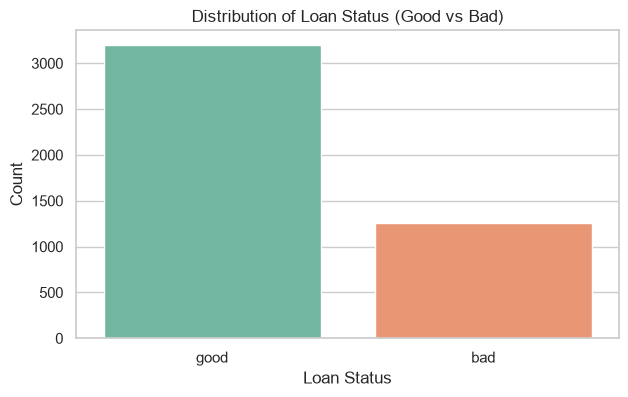

In [25]:
plt.figure(figsize=(7, 4))
sns.countplot(x="Status", data=df, palette="Set2")
plt.title("Distribution of Loan Status (Good vs Bad)")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()

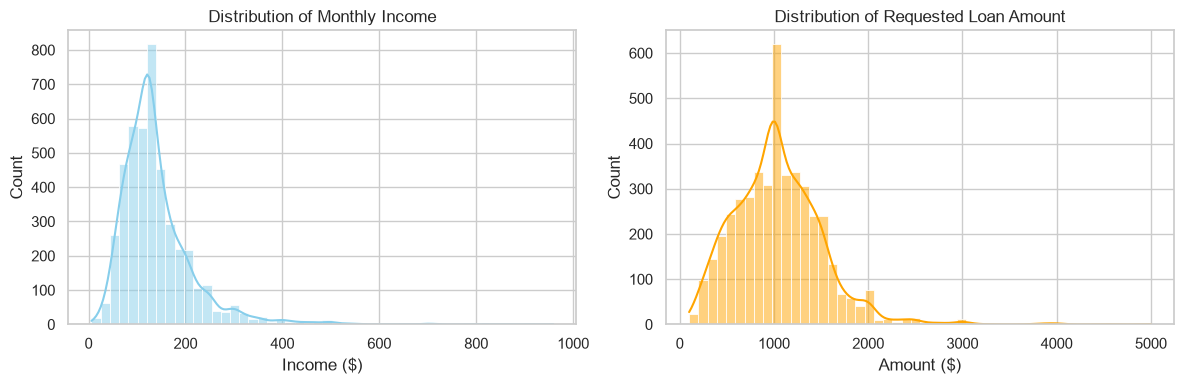

In [26]:
ig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Income"], bins=50, ax=axes[0], color="skyblue", kde=True)
axes[0].set_title("Distribution of Monthly Income")
axes[0].set_xlabel("Income ($)")
sns.histplot(df["Amount"], bins=50, ax=axes[1], color="orange", kde=True)
axes[1].set_title("Distribution of Requested Loan Amount")
axes[1].set_xlabel("Amount ($)")
plt.tight_layout()
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_4332\3211017347.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Status", y=col, data=df, ax=ax, palette="Set2", showfliers=False)
C:\Users\hp\AppData\Local\Temp\ipykernel_4332\3211017347.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Status", y=col, data=df, ax=ax, palette="Set2", showfliers=False)
C:\Users\hp\AppData\Local\Temp\ipykernel_4332\3211017347.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Status", y=col, data=df, ax=ax, palette="Set2", showfliers=False)


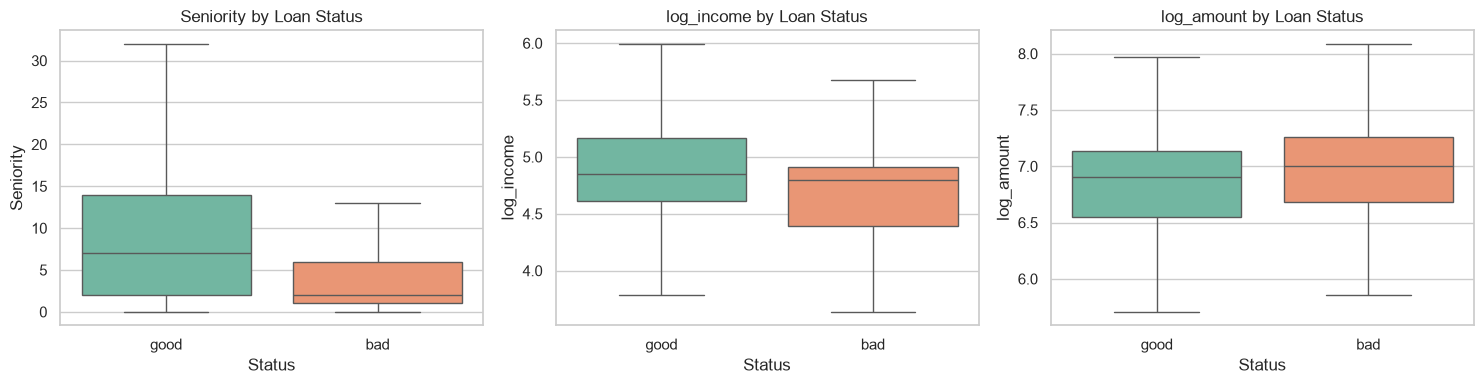

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Seniority", "log_income", "log_amount"]):
    sns.boxplot(x="Status", y=col, data=df, ax=ax, palette="Set2", showfliers=False)
    ax.set_title(f"{col} by Loan Status")
plt.tight_layout()
plt.show()

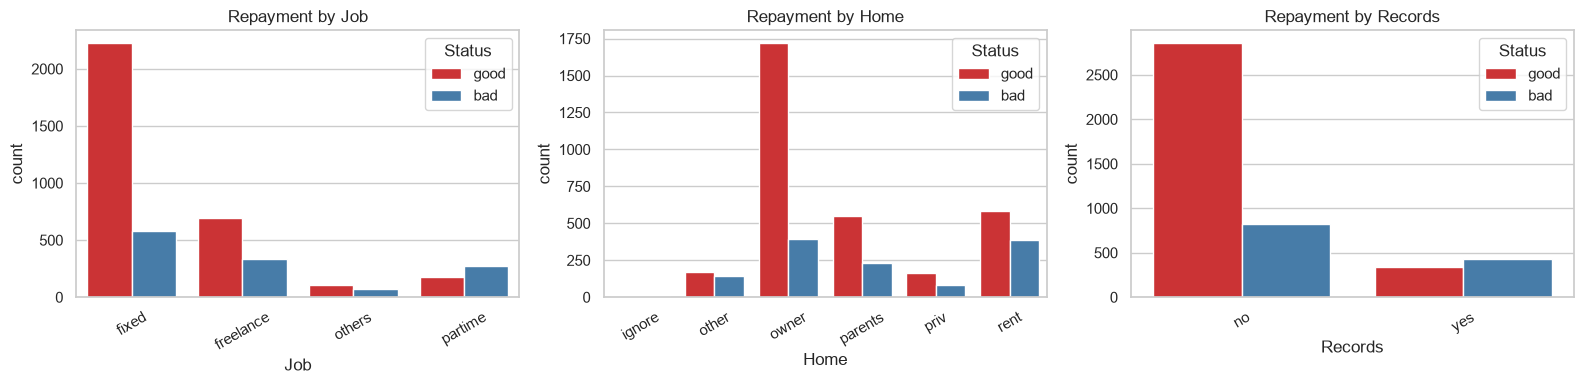

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Job", "Home", "Records"]):
    sns.countplot(x=col, hue="Status", data=df, ax=ax, palette="Set1")
    ax.set_title(f"Repayment by {col}")
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

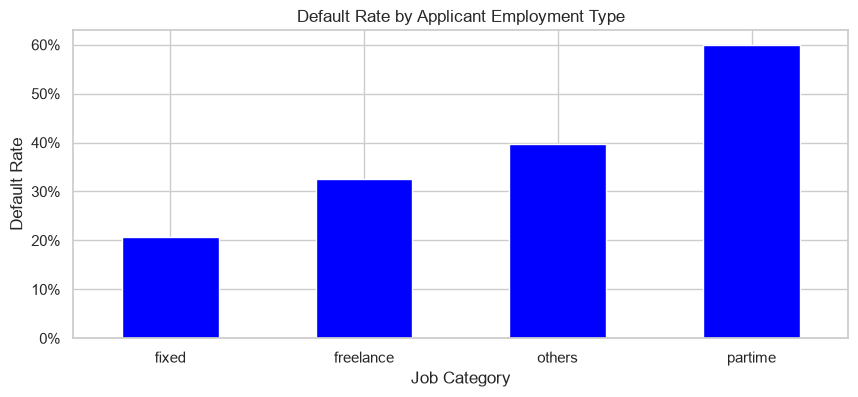

In [29]:
plt.figure(figsize=(10, 4))
df.groupby("Job")["default"].mean().sort_values().plot(kind="bar", color="blue")
plt.title("Default Rate by Applicant Employment Type")
plt.ylabel("Default Rate")
plt.xlabel("Job Category")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.xticks(rotation=0)
plt.show()

In [45]:
corr_matrix = df.select_dtypes(include='number').corr()
print(corr_matrix)

           Seniority      Time       Age  Expenses    Income    Assets  \
Seniority   1.000000 -0.021374  0.505920  0.125873  0.120285  0.125478   
Time       -0.021374  1.000000 -0.051749 -0.000840 -0.037216 -0.083329   
Age         0.505920 -0.051749  1.000000  0.248059  0.138736  0.182523   
Expenses    0.125873 -0.000840  0.248059  1.000000  0.245741  0.018781   
Income      0.120285 -0.037216  0.138736  0.245741  1.000000  0.176414   
Assets      0.125478 -0.083329  0.182523  0.018781  0.176414  1.000000   
Debt       -0.019176  0.058459 -0.046058  0.015155  0.121915  0.191179   
Amount     -0.007913  0.430936  0.029154  0.049200  0.173255  0.144621   
Price       0.040887  0.129674  0.048916  0.040330  0.204419  0.195570   

               Debt    Amount     Price  
Seniority -0.019176 -0.007913  0.040887  
Time       0.058459  0.430936  0.129674  
Age       -0.046058  0.029154  0.048916  
Expenses   0.015155  0.049200  0.040330  
Income     0.121915  0.173255  0.204419  
Assets 

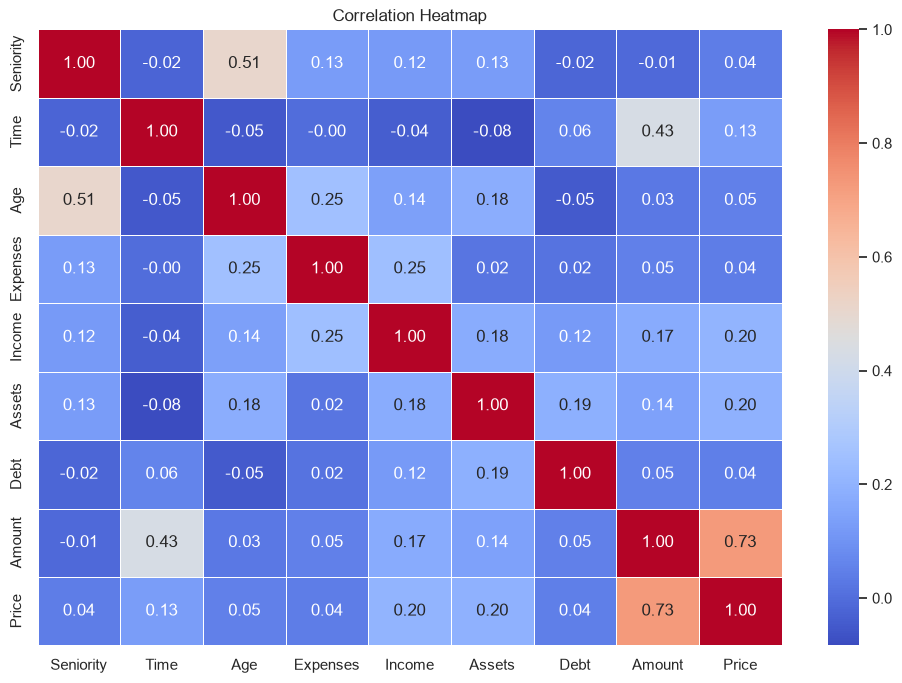

In [44]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

## Key Insights

1. Credit status distribution

Approximately 71.8% of customers (3,200) have good credit status, while 28.2% (1,254) have bad credit status. This shows that most customers have good creditworthiness.

2. Employment seniority and credit status

Customers with good credit status have an average employment seniority of 9.32 years, compared with 4.59 years for bad-credit customers. Seniority has a negative correlation of -0.26 with bad credit status.

3. Income and creditworthiness

Good-credit customers have a higher average income (147.60) than bad-credit customers (121.52). Income has a negative correlation of -0.15 with bad credit status.

4. Loan amount and credit risk

Bad-credit customers have a higher average loan amount (1,156.06) compared with good-credit customers (993.01). Loan amount has a positive correlation of 0.15 with bad credit status.

5. Employment category

Part-time employees have the highest bad-credit rate (59.96%), followed by other employment categories (39.77%), freelance workers (32.52%), and fixed employees (20.73%).

6. Previous credit records

Customers with previous credit records have a higher bad-credit rate (55.5%) than customers without previous credit records (22.4%). This indicates that credit history is useful for understanding credit risk.

7. Relationship between loan amount and price

Loan amount and price have a strong positive correlation of approximately 0.73. This suggests that higher loan amounts are generally associated with higher transaction prices.

8. Income and asset distribution

Income and asset values show right-skewed distributions. This means most customers have relatively moderate values, while a smaller number have considerably higher incomes and assets.